# Day 20 — Practice Session
### Outliers, Matplotlib & Seaborn · Python for Data Science

**Prepared by Srinivasa Sai Chava**  ·  Boston University

---

**Time: 30 minutes** · Attempt everything yourself first.

| Part | Focus | Questions | Suggested time |
|---|---|---|---|
| A | Predict the output (no running!) | 8 | 8 min |
| B | Spot & fix the bug | 4 | 7 min |
| C | Write the code | 5 | 12 min |
| D | Challenge | 2 | 3 min / homework |

> **Every chart must have both axes labelled and a title.** An unlabelled chart is an
> unfinished chart. And print the outlier rows before you treat them.

---
## Setup — run this first

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

np.random.seed(42)
sales = pd.DataFrame({
    "rep":    [f"R{i:02d}" for i in range(30)],
    "region": np.random.choice(["North", "South", "East"], 30),
    "visits": np.random.randint(5, 25, 30),
    "revenue": np.r_[np.random.normal(40000, 6000, 27), [185000, 192000, 205000]].round(0),
})
print("rows:", len(sales))
sales.head()

rows: 30


,rep,region,visits,revenue
0,R00,East,14,32409.0
1,R01,North,20,46552.0
2,R02,East,19,56670.0
3,R03,East,19,47162.0
4,R04,North,23,41312.0


---
# Part A — Predict the Output  *(8 min)*

### A1. What are the bounds?

In [2]:
d = pd.Series([12., 15., 14., 13., 16., 15., 14., 95., 13.])
q1, q3 = d.quantile([.25, .75])
iqr = q3 - q1
print(q1, q3, iqr)
print(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

13.0 15.0 2.0
10.0 18.0


*Your prediction:*  

### A2. Which values are flagged?

In [3]:
d = pd.Series([12., 15., 14., 13., 16., 15., 14., 95., 13.])
lower, upper = 10.0, 18.0
print(d[(d < lower) | (d > upper)].tolist())
print(len(d[(d >= lower) & (d <= upper)]))

[95.0]
8


*Your prediction:*  

### A3. Does the z-score find it?

In [4]:
d = pd.Series([12., 15., 14., 13., 16., 15., 14., 95., 13.])
z = (d - d.mean()) / d.std()
print(round(d.mean(), 2), round(d.std(), 2))
print(round(z.abs().max(), 2))

23.0 27.03
2.66


*Your prediction:*  

### A4. What does clip do?

In [5]:
d = pd.Series([12., 15., 14., 13., 16., 15., 14., 95., 13.])
capped = d.clip(10.0, 18.0)
print(capped.tolist())
print(len(d), len(capped))

[12.0, 15.0, 14.0, 13.0, 16.0, 15.0, 14.0, 18.0, 13.0]
9 9


*Your prediction:*  

### A5. What do these four datasets have in common?

In [6]:
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]
for y in [y1, y2]:
    s = pd.Series(y)
    print(round(s.mean(), 2), round(s.std(), 2), round(pd.Series(x).corr(s), 3))

7.5 2.03 0.816
7.5 2.03 0.816


*Your prediction:*  

### A6. What does subplots return?

In [7]:
fig, ax = plt.subplots()
print(type(ax).__name__)
fig2, axes = plt.subplots(2, 2)
print(axes.shape)
print(type(axes).__name__)
plt.close("all")

Axes
(2, 2)
ndarray


*Your prediction:*  

### A7. What height is bar A?

In [8]:
small = pd.DataFrame({"g": ["A", "A", "B"], "v": [10, 20, 30]})
print(small.groupby("g")["v"].sum().to_dict())
print(small.groupby("g")["v"].mean().to_dict())
# sns.barplot(data=small, x="g", y="v")  -> what would A show?

{'A': 30, 'B': 30}
{'A': 15.0, 'B': 30.0}


*Your prediction:*  

### A8. Does this work?

In [ ]:
df = pd.DataFrame({"a": [1, 2, 3], "b": [2, 4, 7], "name": ["x", "y", "z"]})
print(df.corr())

*Your prediction:*  

---
# Part B — Spot & Fix the Bug  *(7 min)*

### B1. This should find the unusual revenues.

In [ ]:
z = (sales["revenue"] - sales["revenue"].mean()) / sales["revenue"].std()
outliers = sales[z.abs() > 3]
print(f"found {len(outliers)} outliers")

*What's wrong:* 

*Your fix:*

### B2. This should show two charts side by side.

In [ ]:
plt.plot(sales["visits"])
plt.plot(sales["revenue"])
plt.title("Visits and revenue")
plt.show()

*What's wrong:* 

*Your fix:*

### B3. This should show total revenue per region.

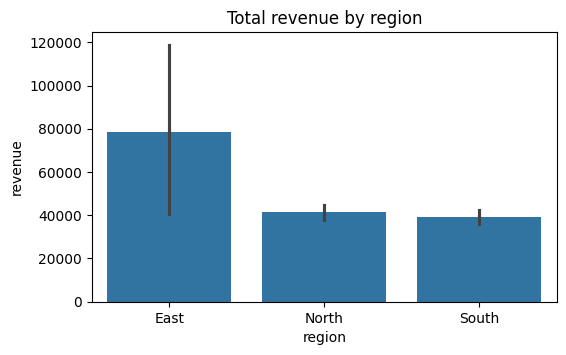

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(data=sales, x="region", y="revenue", ax=ax)
ax.set_title("Total revenue by region")
plt.show()

*What's wrong:* 

*Your fix:*

### B4. This heatmap should show the correlations.

ValueError: could not convert string to float: 'R00'

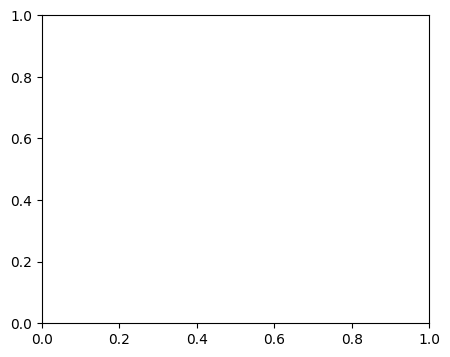

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(sales.corr(), annot=True, ax=ax)
plt.show()

*Error:* 

*Your fix:*

---
# Part C — Write the Code  *(12 min)*

Label every chart.

### C1. Detect and inspect
Using the IQR rule on `revenue`, print the bounds, how many outliers there are, and the
actual rows.

In [ ]:
# your code here

### C2. Compare the treatments
For `revenue`, print the mean, std and row count under three strategies: keep everything,
remove the outliers, and cap them at the IQR bounds.

In [ ]:
# your code here

### C3. A labelled histogram
Plot the distribution of `revenue` with 20 bins. Label both axes, add a title, and draw a
vertical line at the upper IQR bound.

In [ ]:
# your code here

### C4. A grouped comparison
Draw a boxplot of `revenue` by `region`, and say what the dots above the whiskers are.

In [ ]:
# your code here

### C5. A 2×2 overview
Build a single figure with four panels: a histogram of revenue, a boxplot by region, a
scatter of visits against revenue coloured by region, and a correlation heatmap. Title every
panel.

In [ ]:
# your code here

---
# Part D — Challenge  *(3 min, or take home)*

### D1. The outlier you should keep
Three reps have very high revenue. Investigate: are they errors, or are they the finding?
Use the data to argue one way or the other, then say what you would do.

In [ ]:
# your code here

### D2. Make a chart that cannot be misread
Draw the single chart you would put in front of a sales director to explain the revenue
distribution. Then write one sentence saying what it shows.

In [ ]:
# your code here

---
## Done? Self-check

- [ ] I can compute the 1.5 × IQR bounds from memory
- [ ] I know why a z-score can miss its own outlier
- [ ] I printed the outlier rows before deciding anything
- [ ] I know the four treatments and what each costs
- [ ] I used `fig, ax = plt.subplots()` every time
- [ ] Every chart I made has labelled axes and a title
- [ ] I know `sns.barplot` shows the mean, not the sum

### Homework
1. Find the outliers in a dataset by IQR and by z-score, and explain any disagreement.
2. Rebuild the 2×2 overview grid for a dataset of your own.
3. Take one chart and improve it until a classmate reads it correctly.

### Next class — Day 21: Mini project
A full EDA on a real dataset. Load, clean, explore, visualise and write up — everything from
Days 15 to 20, end to end.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*